In [1]:
import os
import torch
import numpy as np
import torch.nn.functional as F
from transformers import AutoModel
import torch.nn as nn
!pip install evaluate
import evaluate
from datasets import load_dataset
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient
from transformers import (
    AutoImageProcessor, 
    AutoModelForImageClassification, 
    TrainingArguments, 
    Trainer
)

print(f"PyTorch: {torch.__version__}")

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 2.8 MB/s eta 0:00:00
PyTorch: 2.10.0+cu128
Using device: cuda


In [2]:
# Hugging Face Authentication
# ==========================================
try:
    user_secrets = UserSecretsClient()
    hf_token = user_secrets.get_secret("HF_TOKEN")
    login(hf_token)
    print("Successfully logged into Hugging Face.")
except Exception as e:
    print("Warning: Could not find HF_TOKEN in Kaggle secrets. Training will fail if the model is gated.")
    print(f"Error: {e}")

Successfully logged into Hugging Face.


In [3]:
# Configuration & Hyperparameters
# ==========================================
DINO_MODEL_ID = "facebook/dinov3-vitb16-pretrain-lvd1689m"
PIXIO_MODEL_ID = "facebook/pixio-vitb16"
DATASET_PATH = "/kaggle/input/datasets/elmadafri/the-wildfire-dataset/the_wildfire_dataset_2n_version"
OUTPUT_DIR = "/kaggle/working/dinov3-wildfire-2n"

BATCH_SIZE = 16
EPOCHS = 10
LEARNING_RATE = 2e-5

In [4]:
# Load and Preprocess Dataset
# ==========================================
print("Loading pre-split dataset...")

# Hugging Face will automatically detect the 'train', 'val', and 'test' folders inside the directory.
dataset = load_dataset("imagefolder", data_dir=DATASET_PATH)

train_ds = dataset['train']
val_ds = dataset['validation'] 
test_ds = dataset['test']

# Create Label Mappings
labels = train_ds.features['label'].names
id2label = {id: label for id, label in enumerate(labels)}
label2id = {label: id for id, label in id2label.items()}
print(f"Classes detected: {id2label}")

# Initialize DINOv3 Image Processor
processor = AutoImageProcessor.from_pretrained(DINO_MODEL_ID)

# Sobel kernels for edge detection (move to GPU if transforming on device, but CPU is safer for HF Datasets)
sobel_x = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]]).view(1, 1, 3, 3)
sobel_y = torch.tensor([[-1., -2., -1.], [0., 0., 0.], [1., 2., 1.]]).view(1, 1, 3, 3)

def extract_edges(rgb_tensor):
    # Convert RGB to Grayscale
    gray = 0.2989 * rgb_tensor[:, 0] + 0.5870 * rgb_tensor[:, 1] + 0.1140 * rgb_tensor[:, 2]
    gray = gray.unsqueeze(1) 
    
    # Apply Sobel Filters
    edge_x = F.conv2d(gray, sobel_x, padding=1)
    edge_y = F.conv2d(gray, sobel_y, padding=1)
    
    magnitude = torch.sqrt(edge_x**2 + edge_y**2)
    # Duplicate to 3 channels for ViT
    return magnitude.repeat(1, 3, 1, 1)

def transform_images(example_batch):
    # Convert all to RGB
    images = [x.convert("RGB") for x in example_batch['image']]
    
    # 1. Process for DINOv3 (Standard 224)
    # Most processors allow you to override the size
    inputs_rgb = processor(images, size={"height": 224, "width": 224}, return_tensors='pt')
    
    # 2. Process for PIXIO (Must be 256)
    inputs_edge = processor(images, size={"height": 256, "width": 256}, return_tensors='pt')
    
    # 3. Generate Edge Maps from the 256x256 tensors
    # This ensures edge_values matches PIXIO's expected input shape
    inputs = {}
    inputs['pixel_values'] = inputs_rgb['pixel_values']
    inputs['edge_values'] = extract_edges(inputs_edge['pixel_values'])
    inputs['labels'] = example_batch['label']
    
    return inputs

def collate_fn(examples):
    # .squeeze() removes the extra batch dimension added by the processor
    pixel_values = torch.stack([torch.as_tensor(example["pixel_values"]).squeeze() for example in examples])
    edge_values = torch.stack([torch.as_tensor(example["edge_values"]).squeeze() for example in examples])
    labels = torch.tensor([example["labels"] for example in examples])
    
    return {
        "pixel_values": pixel_values, 
        "edge_values": edge_values, 
        "labels": labels
    }

# Tell the datasets to use your transform function on-the-fly
train_ds.set_transform(transform_images)
val_ds.set_transform(transform_images)
test_ds.set_transform(transform_images)

print("Transforms applied successfully!")

Loading pre-split dataset...


Resolving data files:   0%|          | 0/1887 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/403 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/410 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Classes detected: {0: 'fire', 1: 'nofire'}


preprocessor_config.json:   0%|          | 0.00/585 [00:00<?, ?B/s]

Transforms applied successfully!


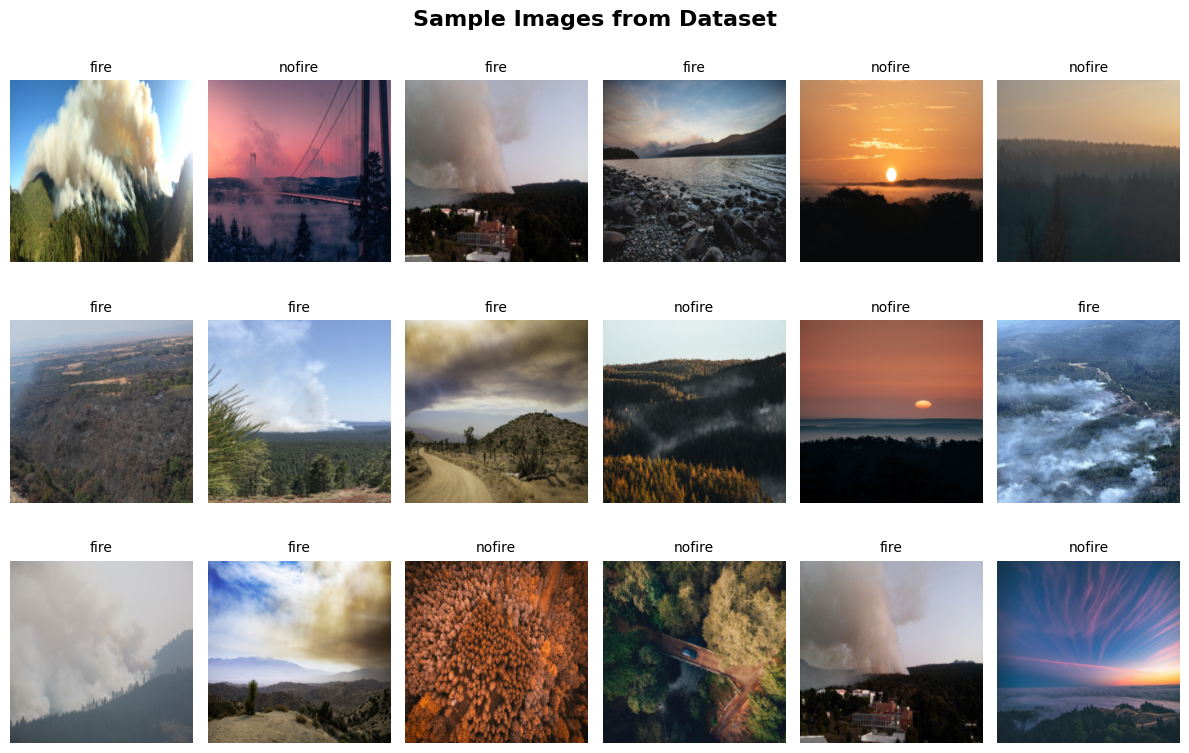

In [5]:
# VISUALIZE SAMPLES 
# ================================
import random
import matplotlib.pyplot as plt

class_names = train_ds.features['label'].names

fig = plt.figure(figsize=(12, 8))
fig.suptitle("Sample Images from Dataset", fontsize=16, fontweight='bold')

rows, cols = 3, 6
for i in range(1, rows * cols + 1):
    idx = random.randint(0, len(train_ds) - 1)
    example = train_ds[idx]

    img = example["pixel_values"]   # tensor (C, H, W)
    label = example["labels"]

    # Convert tensor to numpy
    img_display = img.permute(1, 2, 0).numpy()

    # Denormalize for display
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img_display = img_display * std + mean
    img_display = np.clip(img_display, 0, 1)

    fig.add_subplot(rows, cols, i)
    plt.imshow(img_display)
    plt.title(class_names[label], fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [6]:
from torchinfo import summary
import torch.nn as nn
from transformers import AutoModel

# DINO_MODEL_ID = "facebook/dinov3-vitb16-pretrain-lvd1689m"
# PIXIO_MODEL_ID = "facebook/pixio-vitb16"

print("Loading DINOv3 base backbone...")
backbone1 = AutoModel.from_pretrained(DINO_MODEL_ID)

print("DINOv3 Backbone :- ")
print("="*60)
print(backbone1)

print("Loading Pixio base backbone...")
backbone2 = AutoModel.from_pretrained(PIXIO_MODEL_ID)

print("PIXIO Backbone :- ")
print("="*60)
print(backbone2)

Loading DINOv3 base backbone...


config.json:   0%|          | 0.00/744 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/343M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

DINOv3 Backbone :- 
DINOv3ViTModel(
  (embeddings): DINOv3ViTEmbeddings(
    (patch_embeddings): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  )
  (rope_embeddings): DINOv3ViTRopePositionEmbedding()
  (layer): ModuleList(
    (0-11): 12 x DINOv3ViTLayer(
      (norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (attention): DINOv3ViTAttention(
        (k_proj): Linear(in_features=768, out_features=768, bias=False)
        (v_proj): Linear(in_features=768, out_features=768, bias=True)
        (q_proj): Linear(in_features=768, out_features=768, bias=True)
        (o_proj): Linear(in_features=768, out_features=768, bias=True)
      )
      (layer_scale1): DINOv3ViTLayerScale()
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (mlp): DINOv3ViTMLP(
        (up_proj): Linear(in_features=768, out_features=3072, bias=True)
        (down_proj): Linear(in_features=3072, out_features=768, bias=True)
        (act_fn)

config.json:   0%|          | 0.00/842 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/343M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

PIXIO Backbone :- 
PixioModel(
  (embeddings): PixioEmbeddings(
    (patch_embeddings): PixioPatchEmbeddings(
      (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
    )
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (encoder): PixioEncoder(
    (layer): ModuleList(
      (0-11): 12 x PixioLayer(
        (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (attention): PixioAttention(
          (attention): PixioSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
          )
          (output): PixioSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.0, inplace=False)
          )
        )
        (drop_path): Identity()
        (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      

In [7]:
class HF_DualDomainWildfireModel(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        # Stream 1: RGB (DINOv3)
        self.rgb_vit = AutoModel.from_pretrained('facebook/dinov3-vitb16-pretrain-lvd1689m')
        for param in self.rgb_vit.parameters(): 
            param.requires_grad = False
        
        # Unfreeze last 3 layers of DINOv3
        for layer in self.rgb_vit.layer[-3:]:
            for param in layer.parameters(): 
                param.requires_grad = True
                
        # Stream 2: Edge (PIXIO)
        self.edge_vit = AutoModel.from_pretrained('facebook/pixio-vitb16')
        for param in self.edge_vit.parameters(): 
            param.requires_grad = False # Fixed indentation
        
        # Unfreeze last 3 layers of PIXIO
        for layer in self.edge_vit.encoder.layer[-3:]:
            for param in layer.parameters(): 
                param.requires_grad = True
            
        # Fusion Head (768 from DINO + 768 from PIXIO = 1536)
        self.fusion_classifier = nn.Sequential(
            nn.Linear(768 * 2, 512),
            nn.BatchNorm1d(512),
            nn.GELU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes)
        )
        self.loss_fn = nn.CrossEntropyLoss()

    def forward(self, pixel_values, edge_values, labels=None):
        # Forward pass through both streams
        rgb_outputs = self.rgb_vit(pixel_values=pixel_values)
        edge_outputs = self.edge_vit(pixel_values=edge_values)
        
        # Extract CLS tokens
        rgb_features = rgb_outputs.last_hidden_state[:, 0, :] 
        edge_features = edge_outputs.last_hidden_state[:, 0, :]
        
        # Concatenate (Batch, 1536)
        fused_features = torch.cat((rgb_features, edge_features), dim=1)
        logits = self.fusion_classifier(fused_features)
        
        loss = None
        if labels is not None:
            loss = self.loss_fn(logits, labels)
            
        return {"loss": loss, "logits": logits} if loss is not None else {"logits": logits}

# Instantiate your new custom model
model = HF_DualDomainWildfireModel(num_classes=2).to(device)

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

In [8]:
# Evaluation Metrics
# ==========================================
accuracy_metric = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    return accuracy_metric.compute(predictions=predictions, references=labels)

In [9]:
# Trainer Setup & Execution
# ==========================================
from transformers import Trainer, TrainingArguments
from torch.optim import AdamW

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    remove_unused_columns=False,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=2,
    num_train_epochs=EPOCHS,
    warmup_steps = 500,
    logging_steps=10,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    fp16=True,
    report_to="none"
)

# Custom Optimizer with Differential Learning Rates
optimizer = AdamW([
    {'params': model.rgb_vit.layer[-3:].parameters(), 'lr': 2e-5}, # Changed from .encoder.layer
    {'params': model.edge_vit.encoder.layer[-3:].parameters(), 'lr': 2e-5}, # Kept as .encoder.layer
    {'params': model.fusion_classifier.parameters(), 'lr': 1e-3}
], weight_decay=1e-4)

# Update Trainer initialization to include the custom optimizer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=compute_metrics,
    data_collator=collate_fn,
    optimizers=(optimizer, None) # Pass custom optimizer here, None is for the scheduler
)

print("Starting Dual-Domain training...")
trainer.train()

Starting Dual-Domain training...


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy
1,0.310707,0.271813,0.920398
2,0.146489,0.172691,0.945274
3,0.098481,0.145665,0.962687
4,0.065933,0.157120,0.952736
5,0.053150,0.131002,0.967662
6,0.052687,0.123179,0.972637
7,0.019163,0.135823,0.960199
8,0.022498,0.147528,0.962687
9,0.036199,0.145370,0.965174
10,0.020700,0.189728,0.962687


/usr/local/lib/python3.12/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (104688771 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (89747104 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.12/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (89747104 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (104688771 pixels) exc

TrainOutput(global_step=300, training_loss=0.10319710701704025, metrics={'train_runtime': 16948.0182, 'train_samples_per_second': 1.113, 'train_steps_per_second': 0.018, 'total_flos': 0.0, 'train_loss': 0.10319710701704025, 'epoch': 10.0})

In [10]:
# Save the Final Model
# ==========================================
final_save_path = "/kaggle/working/dualvit-wildfire-2n"
trainer.save_model(final_save_path)
processor.save_pretrained(final_save_path)
print(f"Training complete! Model and processor saved to: {final_save_path}")

Training complete! Model and processor saved to: /kaggle/working/dualvit-wildfire-2n


Generating predictions on the validation dataset...


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]



--- Classification Report ---
              precision    recall  f1-score   support

        fire       0.98      0.95      0.96       156
      nofire       0.97      0.99      0.98       246

    accuracy                           0.97       402
   macro avg       0.97      0.97      0.97       402
weighted avg       0.97      0.97      0.97       402



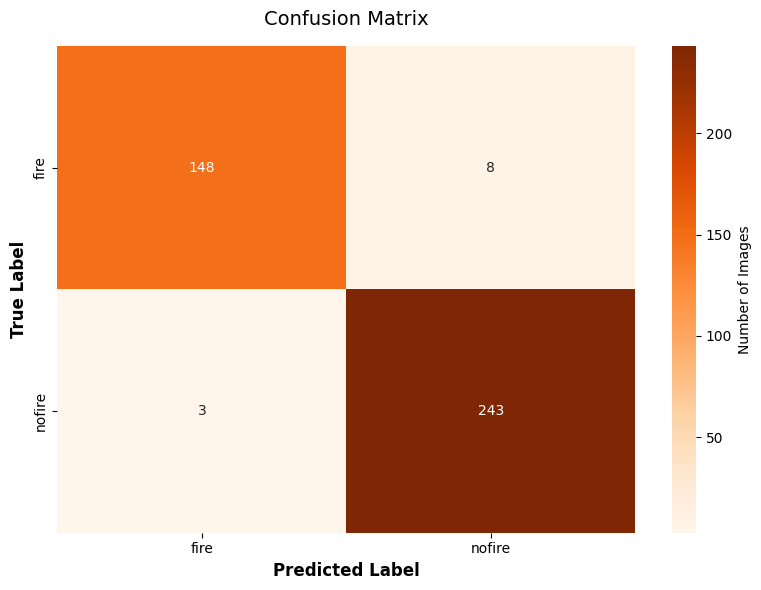

In [11]:
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from scipy.special import softmax
from sklearn.preprocessing import label_binarize

# Generate Predictions on Validation Set
# ==========================================
print("Generating predictions on the validation dataset...")
predictions_output = trainer.predict(val_ds)

# Extract raw logits and true labels
logits = predictions_output.predictions
y_true = predictions_output.label_ids

# Convert logits to probabilities using Softmax
y_probs = softmax(logits, axis=1)

# Get the final predicted classes
y_pred = np.argmax(y_probs, axis=1)

# Comprehensive Metrics Report
# ==========================================
print("\n--- Classification Report ---")
print(classification_report(y_true, y_pred, target_names=labels))

# Plot Confusion Matrix
# ==========================================
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=labels, yticklabels=labels,
            cbar_kws={'label': 'Number of Images'})
plt.xlabel('Predicted Label', fontsize=12, fontweight='bold')
plt.ylabel('True Label', fontsize=12, fontweight='bold')
plt.title('Confusion Matrix', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

Generating predictions on test dataset...


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


/usr/local/lib/python3.12/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (96631920 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (94487082 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (101859328 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(



=== TEST SET CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

        fire     0.9750    0.9811    0.9781       159
      nofire     0.9880    0.9841    0.9860       251

    accuracy                         0.9829       410
   macro avg     0.9815    0.9826    0.9820       410
weighted avg     0.9830    0.9829    0.9829       410


=== TEST SET METRICS ===
Accuracy : 0.9829
Precision: 0.9830
Recall   : 0.9829
F1 Score : 0.9829


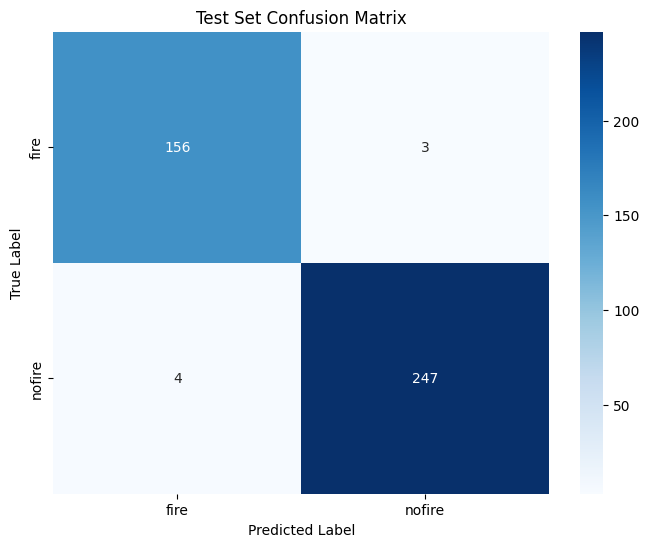

In [12]:
# ==========================================
# Test Set Evaluation
# ==========================================

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.special import softmax
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Generating predictions on test dataset...")

# Predict on test set
test_predictions = trainer.predict(test_ds)

# Extract logits and labels
test_logits = test_predictions.predictions
y_true = test_predictions.label_ids

# Convert logits to probabilities
y_probs = softmax(test_logits, axis=1)

# Predicted classes
y_pred = np.argmax(y_probs, axis=1)

# ==========================================
# Classification Report
# ==========================================
print("\n=== TEST SET CLASSIFICATION REPORT ===")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=labels,
        digits=4
    )
)

# ==========================================
# Overall Metrics
# ==========================================
print("\n=== TEST SET METRICS ===")
print(f"Accuracy : {accuracy_score(y_true, y_pred):.4f}")
print(f"Precision: {precision_score(y_true, y_pred, average='weighted'):.4f}")
print(f"Recall   : {recall_score(y_true, y_pred, average='weighted'):.4f}")
print(f"F1 Score : {f1_score(y_true, y_pred, average='weighted'):.4f}")

# ==========================================
# Confusion Matrix
# ==========================================
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Test Set Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

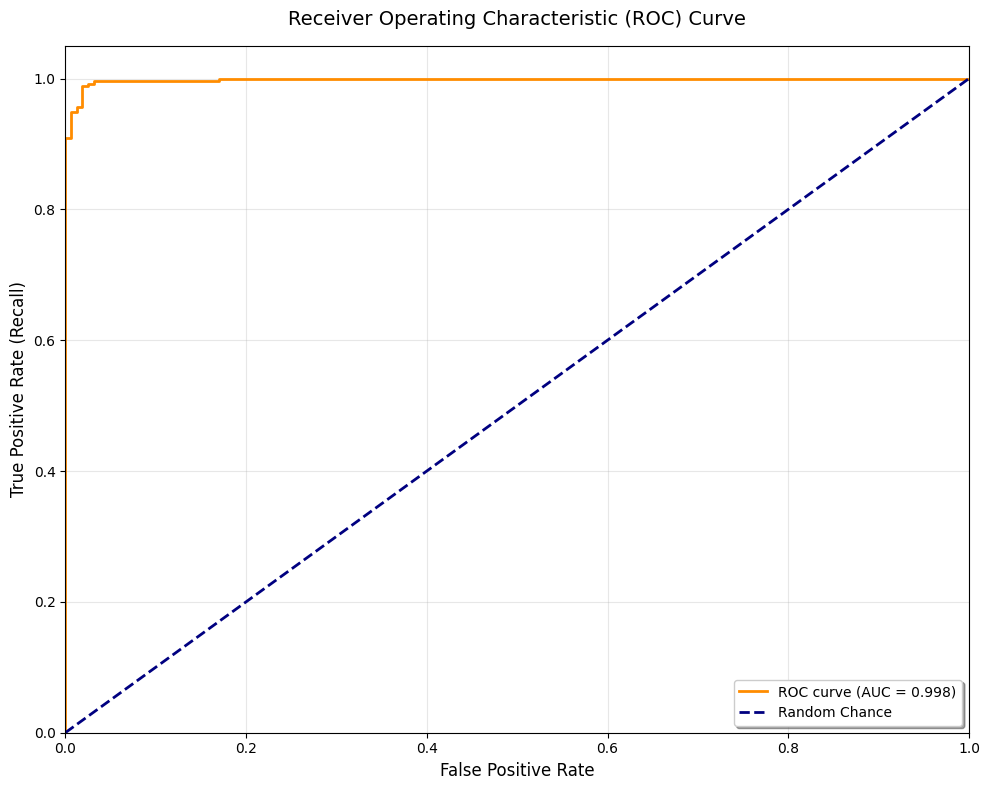

In [13]:
# Plot ROC Curve & Calculate AUC
# ==========================================
plt.figure(figsize=(10, 8))

# Check if binary or multi-class classification
if len(labels) == 2:
    # Binary ROC Curve
    fpr, tpr, thresholds = roc_curve(y_true, y_probs[:, 1])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
else:
    # Multi-class ROC Curve (One-vs-Rest)
    y_true_bin = label_binarize(y_true, classes=range(len(labels)))
    colors = ['darkorange', 'cornflowerblue', 'green', 'red', 'purple']
    
    for i, color in zip(range(len(labels)), colors):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_probs[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, color=color, lw=2, 
                 label=f'{labels[i]} vs Rest (AUC = {roc_auc:.3f})')

# Plot the random chance baseline
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Chance')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate (Recall)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curve', fontsize=14, pad=15)
plt.legend(loc="lower right", frameon=True, shadow=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Generating prediction visualizations...


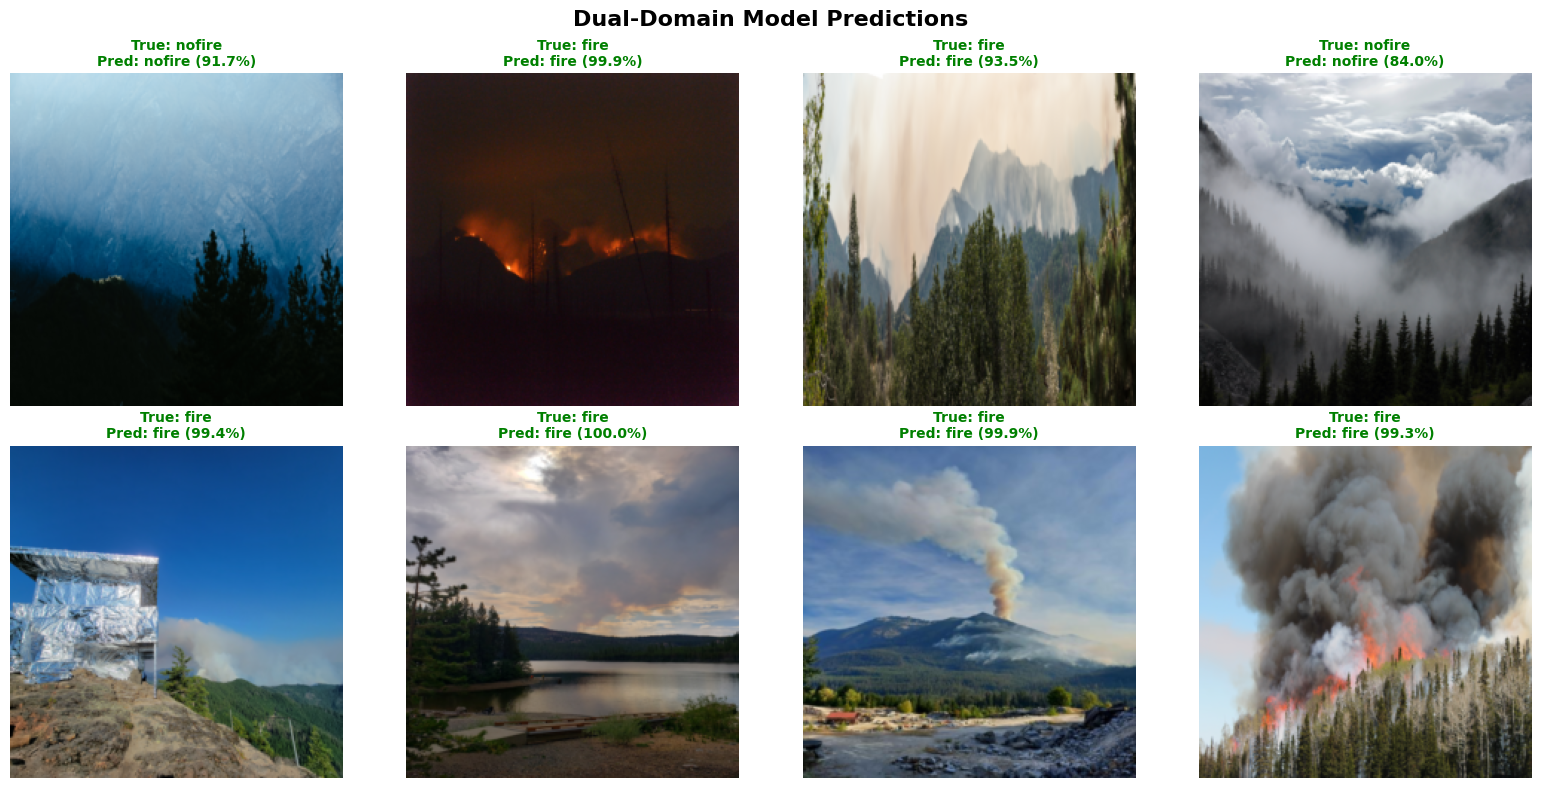

In [14]:
# Visualize Model Predictions
# ==========================================
def visualize_predictions(model, dataset, device, num_samples=8):
    model.eval()
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flatten()
    
    indices = random.sample(range(len(dataset)), num_samples)
    
    with torch.no_grad():
        for i, idx in enumerate(indices):
            item = dataset[idx]
            
            # --- FIX: Prepare both required inputs ---
            pixel_input = item["pixel_values"].unsqueeze(0).to(device)
            edge_input = item["edge_values"].unsqueeze(0).to(device)
            
            label = item["labels"]
            if isinstance(label, torch.Tensor):
                label = label.item()
            
            # --- FIX: Pass both inputs to the model ---
            output = model(pixel_values=pixel_input, edge_values=edge_input)
            logits = output["logits"]
            
            _, pred = torch.max(logits, dim=1)
            prob = torch.softmax(logits, dim=1)[0]
            
            # Use pixel_input for the display (RGB stream)
            img_display = pixel_input.squeeze(0).cpu().permute(1, 2, 0).numpy()
            mean = np.array([0.485, 0.456, 0.406])
            std = np.array([0.229, 0.224, 0.225])
            img_display = img_display * std + mean
            img_display = np.clip(img_display, 0, 1)
            
            axes[i].imshow(img_display)
            color = 'green' if pred.item() == label else 'red'
            
            axes[i].set_title(
                f"True: {id2label[label]}\n"
                f"Pred: {id2label[pred.item()]} ({prob[pred.item()]*100:.1f}%)",
                color=color, fontweight='bold', fontsize=10
            )
            axes[i].axis('off')
    
    plt.suptitle("Dual-Domain Model Predictions", fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

print("\nGenerating prediction visualizations...")
current_device = next(model.parameters()).device
visualize_predictions(model, val_ds, current_device, num_samples=8)

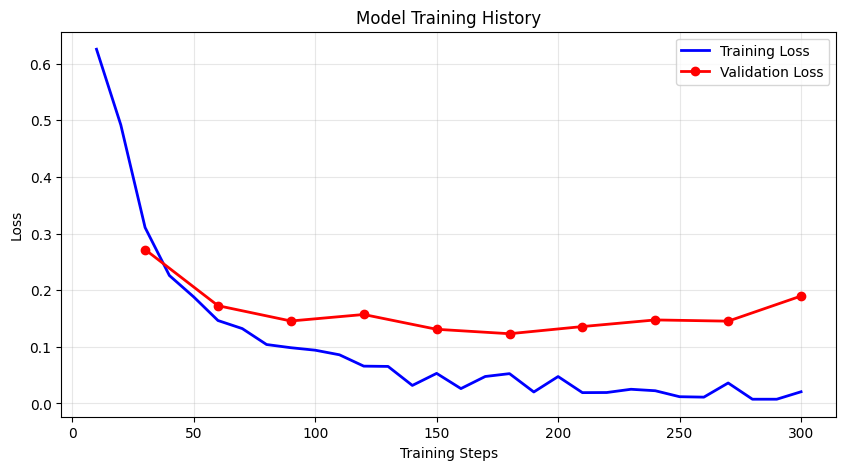

In [15]:
# Plot Training & Validation Loss History
# ==========================================
history = trainer.state.log_history

train_loss = [log['loss'] for log in history if 'loss' in log]
train_steps = [log['step'] for log in history if 'loss' in log]

eval_loss = [log['eval_loss'] for log in history if 'eval_loss' in log]
eval_steps = [log['step'] for log in history if 'eval_loss' in log]

plt.figure(figsize=(10, 5))
if train_loss:
    plt.plot(train_steps, train_loss, label='Training Loss', color='blue', lw=2)
if eval_loss:
    plt.plot(eval_steps, eval_loss, label='Validation Loss', color='red', lw=2, marker='o')

plt.xlabel('Training Steps')
plt.ylabel('Loss')
plt.title('Model Training History')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Testing Image 1: Obvious Wildfire
Fetching image...


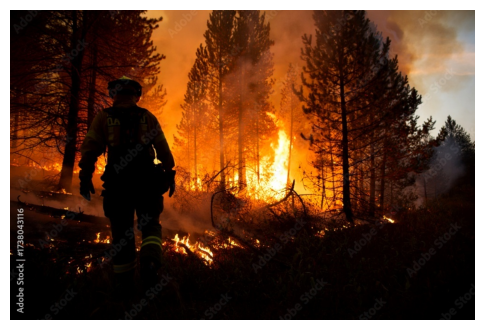

--- Prediction Results ---
Label: FIRE
Confidence: 99.87%
--------------------------

Testing Image 2: Tricky Fog
Fetching image...


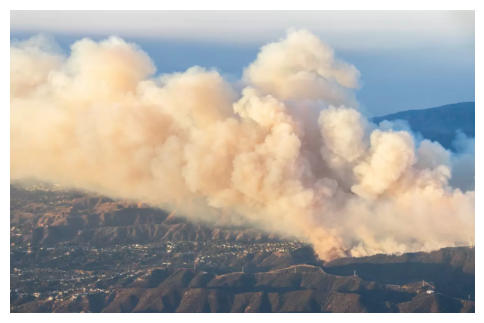

--- Prediction Results ---
Label: FIRE
Confidence: 99.54%
--------------------------

Testing Image 3: Tricky Sunset
Fetching image...


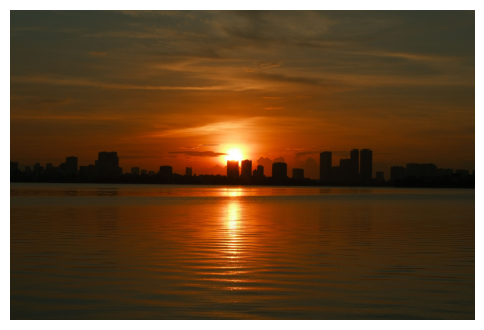

--- Prediction Results ---
Label: NOFIRE
Confidence: 92.62%
--------------------------



In [16]:
import requests
from PIL import Image
from io import BytesIO
import torch.nn.functional as F

def test_wild_image(image_url):
    print("Fetching image...")
    try:
        response = requests.get(image_url, timeout=5)
        response.raise_for_status()
        img = Image.open(BytesIO(response.content)).convert("RGB")
    except Exception as e:
        print(f"Error loading image: {e}")
        return

    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.axis('off')
    plt.show()
    
    # 1. Process for RGB Stream (DINOv3 - 224x224)
    inputs_rgb = processor(images=img, size={"height": 224, "width": 224}, return_tensors="pt")
    
    # 2. Process for Edge Stream (PIXIO - 256x256)
    inputs_edge = processor(images=img, size={"height": 256, "width": 256}, return_tensors="pt")
    
    device = next(model.parameters()).device
    
    # 3. Generate Edge Values using your extract_edges function
    # Ensure kernels are on the right device
    global sobel_x, sobel_y
    sobel_x, sobel_y = sobel_x.to(device), sobel_y.to(device)
    
    pixel_values = inputs_rgb["pixel_values"].to(device)
    edge_tensors = inputs_edge["pixel_values"].to(device)
    edge_values = extract_edges(edge_tensors)
    
    # 4. Generate Prediction with both inputs
    model.eval()
    with torch.no_grad():
        # Manually pass the two required arguments
        outputs = model(pixel_values=pixel_values, edge_values=edge_values)
        logits = outputs["logits"]
        
        probs = F.softmax(logits, dim=1)
        predicted_class_id = torch.argmax(probs, dim=1).item()
        confidence = probs[0][predicted_class_id].item()

    predicted_label = id2label[predicted_class_id]
    print(f"--- Prediction Results ---")
    print(f"Label: {predicted_label.upper()}")
    print(f"Confidence: {confidence * 100:.2f}%")
    print("-" * 26 + "\n")

# Test Cases

# Test 1: A massive, obvious wildfire
print("Testing Image 1: Obvious Wildfire")
test_wild_image("https://as2.ftcdn.net/jpg/17/38/04/31/1000_F_1738043116_n5gpb2rEUNVLCmKrkZXRS4m2m9kfc6Y3.jpg")

# Test 2: A tricky non-fire image (Heavy morning fog looking like smoke)
print("Testing Image 2: Tricky Fog")
test_wild_image("https://ca-times.brightspotcdn.com/dims4/default/9b35fdc/2147483647/strip/true/crop/6000x3917+0+0/resize/1200x783!/format/webp/quality/75/?url=https%3A%2F%2Fcalifornia-times-brightspot.s3.amazonaws.com%2F67%2F1c%2Fa88a72274468a67f9ca47fff0c70%2F1490272-me-socal-fires-flyover-03-mjc.jpg")

# Test 3: A tricky non-fire image (Bright orange sunset through trees)
print("Testing Image 3: Tricky Sunset")
test_wild_image("https://images.pexels.com/photos/33896553/pexels-photo-33896553.jpeg")